# SAEF on Kaggle, estimating the footprint of AI API calls

SAEF (SOMA AI Emission Factors) is an open Python package that turns token counts into estimated carbon and water figures for AI inference. It has no required dependencies and needs no API key. Every number below is an estimate, not a measurement.

This notebook is written for Kaggle. Turn on Internet in the notebook settings so the install cell can reach PyPI. No local files or accounts are needed.

## 1. Install

In [1]:
!pip install -q saef litellm matplotlib

## 2. Estimate one call

We use a call with 2,000 input tokens and 500 output tokens on `gpt-4o`, served from the Stockholm region `eu-north-1`.

In [2]:
import saef

e = saef.estimate(model="gpt-4o", region="eu-north-1", input_tokens=2000, output_tokens=500)
print(f"{e.kg_co2e * 1000:.4f} g CO2e (central estimate)")
print(f"{e.kg_co2e_high_case * 1000:.4f} g CO2e (high case)")
print(f"{e.water_ml:.2f} mL water")
print("grid intensity", e.grid_kg_co2e_per_kwh, "kg CO2e per kWh")

0.0188 g CO2e (central estimate)
0.0247 g CO2e (high case)
1.17 mL water
grid intensity 0.0384 kg CO2e per kWh


The high case is a conservative upper bound. The result also holds the separate terms, so you can see how much comes from electricity, embodied hardware and model training.

In [3]:
for term, kg in e.terms_kg_co2e.items():
    print(f"{term:13s} {kg * 1000:.5f} g CO2e")

electricity   0.00744 g CO2e
embodied      0.00275 g CO2e
construction  0.00124 g CO2e
training      0.00734 g CO2e


## 3. Compare three regions

The same workload gives very different estimates depending on the electricity grid behind the data centre. Here we scale the call above to 1,000 calls.

eu-north-1         18.76 g CO2e per 1000 calls, grid 0.0384 kg CO2e per kWh
us-east-1          70.14 g CO2e per 1000 calls, grid 0.3038 kg CO2e per kWh
ap-southeast-1    108.30 g CO2e per 1000 calls, grid 0.5009 kg CO2e per kWh


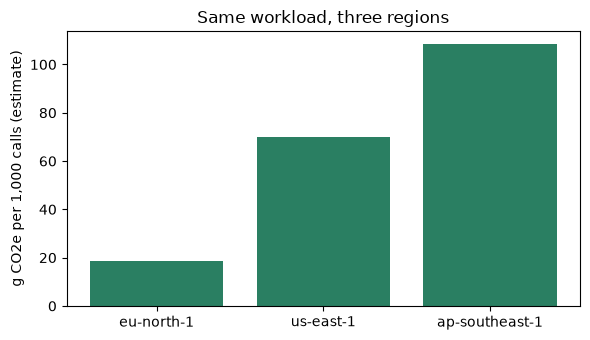

In [4]:
import matplotlib.pyplot as plt

regions = ["eu-north-1", "us-east-1", "ap-southeast-1"]
calls = 1000
grams = {}
for r in regions:
    est = saef.estimate(model="gpt-4o", region=r, input_tokens=2000, output_tokens=500)
    grams[r] = est.kg_co2e * 1000 * calls
    print(f"{r:15s} {grams[r]:8.2f} g CO2e per {calls} calls, grid {est.grid_kg_co2e_per_kwh} kg CO2e per kWh")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(list(grams), list(grams.values()), color="#2a7f62")
ax.set_ylabel("g CO2e per 1,000 calls (estimate)")
ax.set_title("Same workload, three regions")
plt.tight_layout()
plt.show()

## 4. Track calls with a LiteLLM callback

`SaefLogger` listens to every LiteLLM call and keeps running totals. We use `mock_response` so no API key and no network call are needed.

In [5]:
import time
import litellm
from saef.integrations.litellm import SaefLogger

logger = SaefLogger(region="eu-north-1")
litellm.callbacks = [logger]
for _ in range(3):
    litellm.completion(model="gpt-4o-mini", messages=[{"role": "user", "content": "Hello"}], mock_response="Hi there")
time.sleep(1)  # LiteLLM runs success callbacks in a background thread
t = logger.totals()
print(t["calls"], "calls,", t["input_tokens"], "input tokens,", t["output_tokens"], "output tokens")
print(f"{t['kg_co2e']:.3e} kg CO2e, {t['kg_co2e_high_case']:.3e} high case, {t['water_ml']:.4f} mL water")

3 calls, 30 input tokens, 60 output tokens
2.662e-07 kg CO2e, 3.793e-07 high case, 0.0224 mL water


LangChain has the same pattern. See the package README for `SaefCallbackHandler` and the newer `SaefMiddleware`.

## 5. How to cite

If you use these figures, cite the dataset. `saef.citation()` returns a BibTeX entry for the version you have installed.

In [6]:
print(saef.citation())
print("dataset version", saef.DATASET_VERSION)

@misc{llopis2026somafactors,
  author       = {Llopis-Garcia, Guillermo},
  title        = {{SOMA AI Emission Factors (SAEF)}},
  year         = {2026},
  publisher    = {Zenodo},
  version      = {v3.1.0},
  doi          = {10.5281/zenodo.20443585},
  url          = {https://doi.org/10.5281/zenodo.20443585}
}

@misc{llopis2026accounting,
  author        = {Llopis-Garcia, Guillermo},
  title         = {Accounting for Purchased Artificial Intelligence Inference in Corporate Greenhouse Gas Inventories: A Token-Based Method},
  year          = {2026},
  eprint        = {2606.10660},
  archivePrefix = {arXiv},
  note          = {Accepted for publication in Sustainable Production and Consumption (Elsevier)}
}

dataset version 3.1.0


## Links

- Source code and issues on [GitHub](https://github.com/guillermollopis/soma-ai-emission-factors)
- Package on [PyPI](https://pypi.org/project/saef/)
- Dataset on [Zenodo](https://doi.org/10.5281/zenodo.20443585)
- Paper on [arXiv](https://arxiv.org/abs/2606.10660)